# 01 EDA: PathSnap dataset (train and student_test)
Every table and plot is labelled by partition. Distances use the per-trip UTM projection from `src/geo.py`. Outputs go to `results/eda/`.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.data_io import load_trip
from src.geo import TripProjection
OUT = Path("results/eda"); OUT.mkdir(parents=True, exist_ok=True)
PARTITIONS = ["train", "student_test"]
pd.set_option("display.width", 200)

## Per-trip statistics (one pass over all trips)
`load_trip` sorts by t, drops NaN/out-of-range coordinates and duplicate timestamps, and logs the counts in `track.attrs`.

In [2]:
rows, tracks = [], {}
for part in PARTITIONS:
    for d in sorted(Path("data", part).iterdir()):
        trip = load_trip(d)
        tr, nodes, arcs, route = trip["track"], trip["nodes"], trip["arcs"], trip["route"]
        tracks[(part, d.name)] = tr
        dt = tr["t"].diff().dropna()
        x, y = TripProjection.from_coordinates(tr["lon"].values, tr["lat"].values).project(tr["lon"].values, tr["lat"].values)
        g = nx.DiGraph()
        g.add_nodes_from(range(len(nodes)))
        g.add_edges_from(map(tuple, arcs))
        chain = [arcs[a, 1] == arcs[b, 0] for a, b in zip(route[:-1], route[1:])] if route else []
        files = list(d.iterdir())
        rows.append({
            "partition": part, "trip_id": d.name,
            "n_files": len(files), "size_kb": sum(f.stat().st_size for f in files) / 1024,
            "raw_points": len(tr) + tr.attrs["invalid_rows_removed"] + tr.attrs["duplicate_timestamps_removed"],
            "points": len(tr),
            "invalid_removed": tr.attrs["invalid_rows_removed"],
            "duplicate_t_removed": tr.attrs["duplicate_timestamps_removed"],
            "raw_sorted_by_t": bool((tr["original_idx"].diff().dropna() > 0).all()),
            "share_1s_steps": float((dt == 1).mean()),
            "max_gap_s": float(dt.max()), "n_gaps_gt_1_5s": int((dt > 1.5).sum()),
            "duration_s": float(tr["t"].iloc[-1] - tr["t"].iloc[0]),
            "lon_min": tr["lon"].min(), "lon_max": tr["lon"].max(),
            "lat_min": tr["lat"].min(), "lat_max": tr["lat"].max(),
            "extent_x_km": (x.max() - x.min()) / 1000, "extent_y_km": (y.max() - y.min()) / 1000,
            "path_km": float(np.hypot(np.diff(x), np.diff(y)).sum() / 1000),
            "nodes": len(nodes), "arcs": len(arcs),
            "weak_components": nx.number_weakly_connected_components(g),
            "largest_component_share": len(max(nx.weakly_connected_components(g), key=len)) / len(nodes),
            "isolated_nodes": nx.number_of_isolates(g),
            "route_arcs": len(route) if route else 0,
            "route_chain_share": float(np.mean(chain)) if chain else np.nan,
            "route_repeated_arcs": len(route) - len(set(route)) if route else 0,
        })
stats = pd.DataFrame(rows)
stats.to_csv(OUT / "per_trip_stats.csv", index=False)
print(len(stats), "trips processed")

90 trips processed


## 1. Trip inventory

In [3]:
inv = stats.groupby("partition").agg(trips=("trip_id", "count"), files=("n_files", "sum"),
    total_size_mb=("size_kb", lambda s: s.sum() / 1024), points_total=("points", "sum"),
    points_min=("points", "min"), points_median=("points", "median"), points_max=("points", "max"))
inv.to_csv(OUT / "inventory.csv"); inv

,trips,files,total_size_mb,points_total,points_min,points_median,points_max
partition,,,,,,,
student_test,10,40,4.166213,19160,262,1420.0,3958
train,80,320,85.580303,208417,361,1529.0,19313


## 2. Data types and column names (files have no header; names come from the dataset document)

In [4]:
names = {"track": ["lon", "lat", "t"], "nodes": ["lon", "lat"], "arcs": ["from_node", "to_node"], "route": ["arc_id"]}
dt_rows = []
for part in PARTITIONS:
    d = sorted(Path("data", part).iterdir())[0]
    for ext, cols in names.items():
        df = pd.read_csv(d / f"{d.name}.{ext}", sep=r"\s+", header=None, names=cols)
        dt_rows += [{"partition": part, "example_trip": d.name, "file": ext, "column": c, "dtype": str(df[c].dtype),
                     "example_value": df[c].iloc[0]} for c in cols]
dtypes = pd.DataFrame(dt_rows); dtypes.to_csv(OUT / "dtypes.csv", index=False); dtypes

,partition,example_trip,file,column,dtype,example_value
0,train,00000001,track,lon,float64,8.595203
1,train,00000001,track,lat,float64,49.844053
2,train,00000001,track,t,float64,1.000000
3,train,00000001,nodes,lon,float64,8.581679
4,train,00000001,nodes,lat,float64,49.857880
5,train,00000001,arcs,from_node,int64,0.000000
6,train,00000001,arcs,to_node,int64,281.000000
7,train,00000001,route,arc_id,int64,2641.000000
8,student_test,00000000,track,lon,float64,54.963519
9,student_test,00000000,track,lat,float64,56.251559


## 3. Missing and invalid values (cleaning log from `data_io.load_trip`)

In [5]:
miss = stats.groupby("partition")[["raw_points", "invalid_removed", "duplicate_t_removed", "points"]].sum()
miss["trips_not_sorted_by_t"] = stats.groupby("partition")["raw_sorted_by_t"].apply(lambda s: int((~s).sum()))
miss.to_csv(OUT / "missing_invalid.csv"); miss

,raw_points,invalid_removed,duplicate_t_removed,points,trips_not_sorted_by_t
partition,,,,,
student_test,19160,0,0,19160,0
train,208417,0,0,208417,0


## 4. Timestamp ordering, 1 s steps and gaps

In [6]:
ts = stats.groupby("partition").agg(share_1s_steps_mean=("share_1s_steps", "mean"),
    gaps_gt_1_5s_total=("n_gaps_gt_1_5s", "sum"), max_gap_s=("max_gap_s", "max"), median_max_gap_s=("max_gap_s", "median"))
ts.to_csv(OUT / "timestamps.csv")
# unusual = largest gap above 60 s (one minute without GPS covers several road segments)
big = stats.loc[stats["max_gap_s"] > 60, ["partition", "trip_id", "points", "max_gap_s", "n_gaps_gt_1_5s", "share_1s_steps"]]
big = big.sort_values("max_gap_s", ascending=False); big.to_csv(OUT / "trips_large_gaps.csv", index=False)
display(ts); big

,share_1s_steps_mean,gaps_gt_1_5s_total,max_gap_s,median_max_gap_s
partition,,,,
student_test,0.981990,264,210.0,2.0
train,0.938296,7273,153064.0,11.0


,partition,trip_id,points,max_gap_s,n_gaps_gt_1_5s,share_1s_steps
72,train,00000090,536,153064.0,224,0.581308
61,train,00000078,2909,52810.0,712,0.755158
55,train,00000069,2067,2658.0,22,0.989351
16,train,00000021,15783,2161.0,6,0.999620
8,train,00000011,2828,909.0,1,0.999646
34,train,00000042,7739,670.0,81,0.989532
64,train,00000081,3224,536.0,903,0.719826
18,train,00000024,801,458.0,23,0.971250
36,train,00000044,546,341.0,54,0.900917
67,train,00000084,16031,312.0,50,0.996881


## 5. Geographical extent per trip

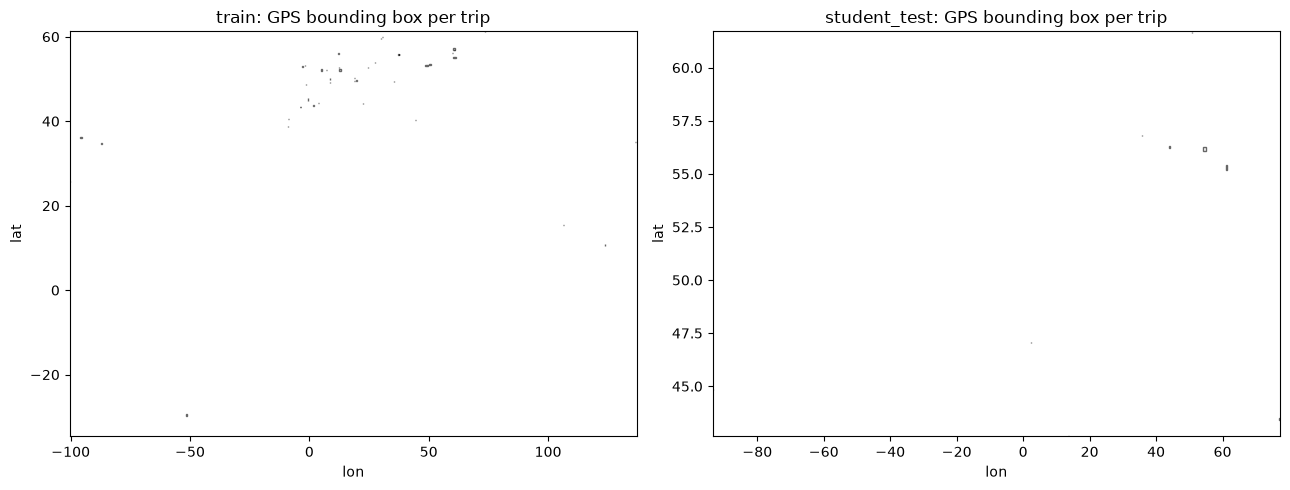

extent_x_km                                               extent_y_km         ...               path_km                                                
                   count   mean    std   min   25%   50%    75%    max       count   mean  ...    75%    max   count   mean    std   min    25%    50%   75%     max
partition                                                                                  ...                                                                      
student_test        10.0   9.93  12.93  2.19  3.21  5.29  10.39  45.04        10.0   9.14  ...  11.64  27.08    10.0  29.75  22.87  5.56  12.18  20.96  48.5   71.78
train               80.0  14.09  16.26  0.88  3.34  7.63  17.07  70.92        80.0  11.91  ...  14.01  75.08    80.0  37.27  34.52  6.34  12.80  24.05  48.8  169.55

[2 rows x 24 columns]

In [7]:
ext = stats[["partition", "trip_id", "lon_min", "lon_max", "lat_min", "lat_max", "extent_x_km", "extent_y_km", "path_km"]]
ext.to_csv(OUT / "extent.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, part in zip(axes, PARTITIONS):
    for _, r in ext[ext.partition == part].iterrows():
        ax.add_patch(plt.Rectangle((r.lon_min, r.lat_min), r.lon_max - r.lon_min, r.lat_max - r.lat_min, fill=False, alpha=0.6))
    s = ext[ext.partition == part]
    ax.set_xlim(s.lon_min.min() - 0.01, s.lon_max.max() + 0.01); ax.set_ylim(s.lat_min.min() - 0.01, s.lat_max.max() + 0.01)
    ax.set_title(f"{part}: GPS bounding box per trip"); ax.set_xlabel("lon"); ax.set_ylabel("lat")
fig.tight_layout(); fig.savefig(OUT / "extent_boxes.png", dpi=120); plt.show()
ext.groupby("partition")[["extent_x_km", "extent_y_km", "path_km"]].describe().round(2)

## 6. Road network size and connectivity (networkx DiGraph, weak components; all trips)

In [8]:
net = stats[["partition", "trip_id", "nodes", "arcs", "weak_components", "largest_component_share", "isolated_nodes"]]
net.to_csv(OUT / "network.csv", index=False)
net.groupby("partition").describe().T.round(3)

partition                      student_test       train
nodes                   count        10.000      80.000
                        mean       9068.900   24168.562
                        std        7452.176   32272.296
                        min        1770.000     299.000
                        25%        4908.000    3487.750
                        50%        6596.500    9608.000
                        75%       11844.250   28846.750
                        max       26635.000  155003.000
arcs                    count        10.000      80.000
                        mean      18504.100   48461.300
                        std       15496.930   64738.837
                        min        3577.000     649.000
                        25%       10292.250    7061.750
                        50%       13145.000   19526.500
                        75%       24818.500   58003.250
                        max       56027.000  307392.000
weak_components         count        10.000      80.000
                        mean         22.700      39.012
                        std          29.182      60.682
                        min           5.000       1.000
                        25%           7.250       9.750
                        50%          11.000      20.000
                        75%          21.750      42.250
                        max         100.000     421.000
largest_component_share count        10.000      80.000
                        mean          0.964       0.969
                        std           0.034       0.039
                        min           0.874       0.693
                        25%           0.964       0.963
                        50%           0.971       0.981
                        75%           0.983       0.987
                        max           0.991       1.000
isolated_nodes          count        10.000      80.000
                        mean          0.000       0.000
                        std           0.000       0.000
                        min           0.000       0.000
                        25%           0.000       0.000
                        50%           0.000       0.000
                        75%           0.000       0.000
                        max           0.000       0.000

## 7. Route structure: is `.route` a connected arc chain?
`route_chain_share` = share of consecutive route arcs where `to_node` of one equals `from_node` of the next.

In [9]:
rs = stats[["partition", "trip_id", "route_arcs", "route_chain_share", "route_repeated_arcs"]]
rs.to_csv(OUT / "route_structure.csv", index=False)
display(rs.groupby("partition").agg(route_arcs_median=("route_arcs", "median"),
    chain_share_mean=("route_chain_share", "mean"), chain_share_min=("route_chain_share", "min"),
    trips_fully_connected=("route_chain_share", lambda s: int((s == 1).sum()))))
rs[rs.route_chain_share < 1]

,route_arcs_median,chain_share_mean,chain_share_min,trips_fully_connected
partition,,,,
student_test,250.0,0.999732,0.997319,9
train,280.0,0.999346,0.981308,70


,partition,trip_id,route_arcs,route_chain_share,route_repeated_arcs
1,train,00000002,262,0.996169,0
14,train,00000019,545,0.994485,0
26,train,00000033,169,0.994048,0
33,train,00000041,340,0.997050,0
34,train,00000042,1440,0.999305,0
55,train,00000069,467,0.997854,29
60,train,00000075,108,0.981308,2
63,train,00000080,139,0.992754,0
69,train,00000086,671,0.998507,2
71,train,00000089,265,0.996212,0


## 8. Plots

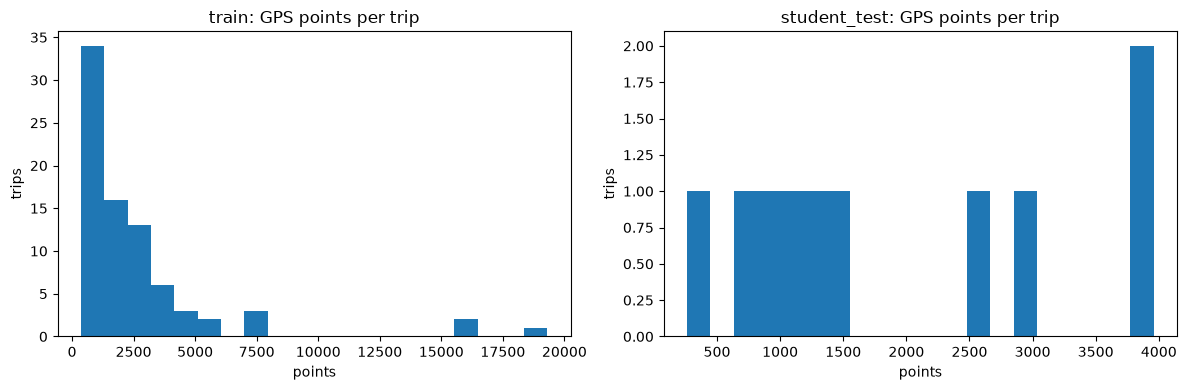

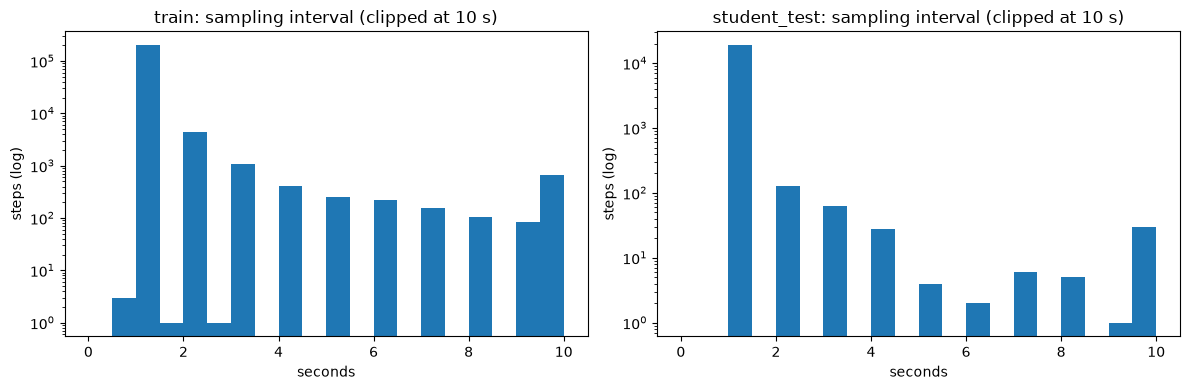

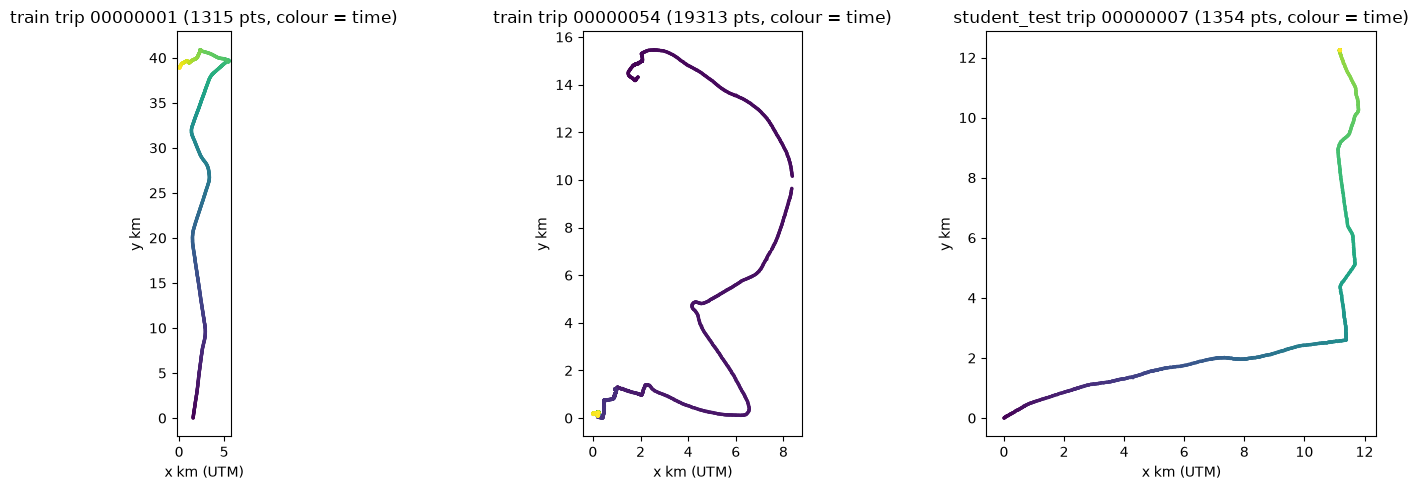

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, part in zip(axes, PARTITIONS):
    ax.hist(stats.loc[stats.partition == part, "points"], bins=20)
    ax.set_title(f"{part}: GPS points per trip"); ax.set_xlabel("points"); ax.set_ylabel("trips")
fig.tight_layout(); fig.savefig(OUT / "points_per_trip_hist.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, part in zip(axes, PARTITIONS):
    dts = np.concatenate([tr["t"].diff().dropna().values for (p, _), tr in tracks.items() if p == part])
    ax.hist(np.clip(dts, 0, 10), bins=np.arange(0, 10.5, 0.5), log=True)
    ax.set_title(f"{part}: sampling interval (clipped at 10 s)"); ax.set_xlabel("seconds"); ax.set_ylabel("steps (log)")
fig.tight_layout(); fig.savefig(OUT / "sampling_interval_hist.png", dpi=120); plt.show()

picks = [("train", "00000001"), ("train", stats[stats.partition == "train"].sort_values("points").trip_id.iloc[-1]), ("student_test", "00000007")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (part, tid) in zip(axes, picks):
    tr = tracks[(part, tid)]
    x, y = TripProjection.from_coordinates(tr.lon.values, tr.lat.values).project(tr.lon.values, tr.lat.values)
    ax.scatter((x - x.min()) / 1000, (y - y.min()) / 1000, c=tr.t, s=2, cmap="viridis")
    ax.set_title(f"{part} trip {tid} ({len(tr)} pts, colour = time)"); ax.set_xlabel("x km (UTM)"); ax.set_ylabel("y km"); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(OUT / "trajectories_3_trips.png", dpi=120); plt.show()

## 9. Folium maps (from `src/maps.py`)
Saved maps: [train 00000001](../results/maps/train_00000001.html), [student_test 00000007](../results/maps/student_test_00000007.html). Layers: GPS points (blue), road network (grey), reference route (green), start/end markers.

In [11]:
from src.maps import make_map
make_map(load_trip("data/train/00000001"), out_path="results/maps/train_00000001.html")
make_map(load_trip("data/student_test/00000007"), out_path="results/maps/student_test_00000007.html")
print("maps written to results/maps/ (open the HTML files in a browser)")

maps written to results/maps/ (open the HTML files in a browser)


## 10. Data-quality issues, assumptions and decisions (numbers computed above)

In [12]:
t, s = stats[stats.partition == "train"], stats[stats.partition == "student_test"]
dq = pd.DataFrame([
    ["Invalid / NaN coordinates", f"train {t.invalid_removed.sum()}, student_test {s.invalid_removed.sum()} rows",
     "Invalid rows carry no position", "Dropped in data_io.load_trip"],
    ["Duplicate timestamps", f"train {t.duplicate_t_removed.sum()}, student_test {s.duplicate_t_removed.sum()} rows",
     "Same second = same fix", "Keep first, drop rest"],
    ["Unsorted timestamps", f"{int((~stats.raw_sorted_by_t).sum())} trips", "Order is time order", "Sort by t (stable)"],
    ["Time gaps > 1.5 s", f"train {t.n_gaps_gt_1_5s.sum()}, student_test {s.n_gaps_gt_1_5s.sum()} gaps; {len(big)} trips with a gap > 60 s",
     "Vehicle kept moving during gaps", "Flag with is_gap_after; HMM relaxes transitions over gaps"],
    ["Different regions (train vs student_test)", f"train lon {t.lon_min.min():.2f}..{t.lon_max.max():.2f}, student_test lon {s.lon_min.min():.2f}..{s.lon_max.max():.2f}",
     "Degrees are not metres; location must not leak", "Per-trip UTM projection; no raw lat/lon features"],
    ["Disconnected network pieces", f"median weak components: train {t.weak_components.median():.0f}, student_test {s.weak_components.median():.0f}",
     "Small pieces are clipping artefacts at the network border", "Keep all arcs as candidates; HMM uses graph distance"],
    ["Isolated nodes", f"train {t.isolated_nodes.sum()}, student_test {s.isolated_nodes.sum()}", "Nodes without arcs cannot be matched", "Ignored (candidates are arcs)"],
    ["Route not a perfect chain", f"mean chain share train {t.route_chain_share.mean():.4f}, student_test {s.route_chain_share.mean():.4f}",
     "Route is reference information, not verified truth", "Derive point labels monotonically; report label mismatch rate"],
    ["No GPS-point-to-arc mapping", f"route arcs per point: train {t.route_arcs.sum() / t.points.sum():.2f}",
     "Point lies on the nearest of the next few route arcs", "src/labels.py monotonic labelling"],
], columns=["issue", "evidence", "assumption", "decision"])
dq.to_csv(OUT / "data_quality.csv", index=False); dq

,issue,evidence,assumption,decision
0,Invalid / NaN coordinates,"train 0, student_test 0 rows",Invalid rows carry no position,Dropped in data_io.load_trip
1,Duplicate timestamps,"train 0, student_test 0 rows",Same second = same fix,"Keep first, drop rest"
2,Unsorted timestamps,0 trips,Order is time order,Sort by t (stable)
3,Time gaps > 1.5 s,"train 7273, student_test 264 gaps; 23 trips wi...",Vehicle kept moving during gaps,Flag with is_gap_after; HMM relaxes transition...
4,Different regions (train vs student_test),"train lon -100.42..137.24, student_test lon -9...",Degrees are not metres; location must not leak,Per-trip UTM projection; no raw lat/lon features
5,Disconnected network pieces,"median weak components: train 20, student_test 11",Small pieces are clipping artefacts at the net...,Keep all arcs as candidates; HMM uses graph di...
6,Isolated nodes,"train 0, student_test 0",Nodes without arcs cannot be matched,Ignored (candidates are arcs)
7,Route not a perfect chain,"mean chain share train 0.9993, student_test 0....","Route is reference information, not verified t...",Derive point labels monotonically; report labe...
8,No GPS-point-to-arc mapping,route arcs per point: train 0.15,Point lies on the nearest of the next few rout...,src/labels.py monotonic labelling
